# 04. 분포 · 시계열 · 계절성

가격과 4주 변화율의 분포, 대표 품목의 흐름, 매년 반복되는 계절 패턴, 가격과 관련 변수를 같은 시간축에 놓고 보기.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parents[1]                     # demo/2_eda → 프로젝트 루트
P = ROOT / "data" / "processed"
NAMES = {"agri": "농산물", "livestock": "축산물", "fishery": "수산물"}
plt.rcParams.update({"font.family": "Malgun Gothic", "axes.unicode_minus": False, "figure.dpi": 110})
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:,.3f}".format)

In [2]:
# 전국 소매가 + 모든 변수 (원본 값): data/processed/{분야}/dataset.parquet
# 예측 대상은 소매가 → 소매 시계열만. 중도매가는 피처(whsl_price_kg 등 열)로만 쓰임
ds = {d: pd.read_parquet(P / d / "dataset.parquet", filters=[("se_nm", "==", "소매")]) for d in NAMES}
ds = {d: df[df.date >= "2016-01-01"] for d, df in ds.items()}     # 2015년은 이력 계산용 준비 기간
{NAMES[d]: df.shape for d, df in ds.items()}

{'농산물': (284054, 116), '축산물': (62275, 111), '수산물': (66874, 136)}

## 1. 가격 분포 (시계열별 평균 소매가, log)

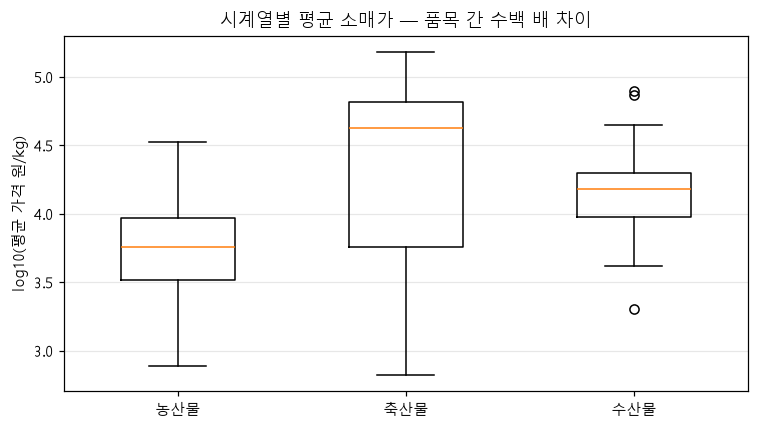

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
data = [np.log10(df.groupby(["item_nm", "vrty_nm", "grd_nm"]).price_kg.mean()) for df in ds.values()]
ax.boxplot(data, tick_labels=list(NAMES.values()), widths=0.5)
ax.set_ylabel("log10(평균 가격 원/kg)"); ax.set_title("시계열별 평균 소매가 — 품목 간 수백 배 차이"); ax.grid(axis="y", alpha=0.3); plt.tight_layout()

## 2. 4주 변화율 분포

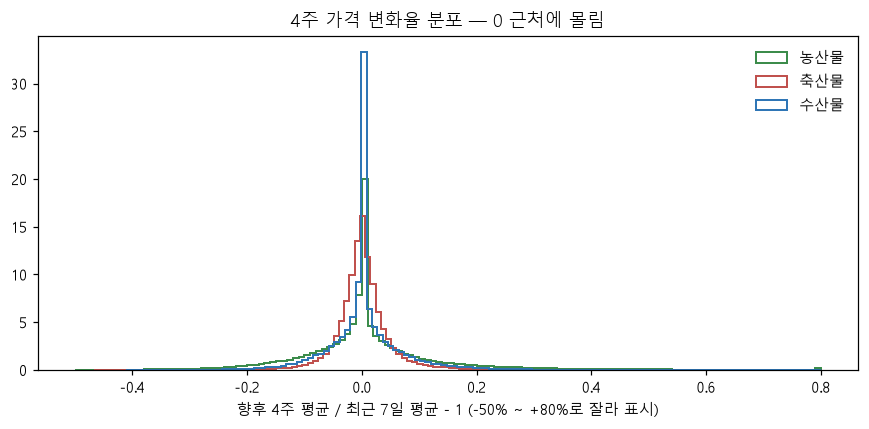

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for (d, c) in zip(NAMES, ["#3b8c4a", "#c0504d", "#2e75b6"]):
    v = pd.read_parquet(P / d / "features.parquet", columns=["date", "y"], filters=[("se_nm", "==", "소매")]).query("date >= '2016-01-01'").y
    ax.hist(v.clip(-0.5, 0.8), bins=130, histtype="step", density=True, color=c, lw=1.3, label=NAMES[d])
ax.set_xlabel("향후 4주 평균 / 최근 7일 평균 - 1 (-50% ~ +80%로 잘라 표시)"); ax.set_title("4주 가격 변화율 분포 — 0 근처에 몰림"); ax.legend(frameon=False); plt.tight_layout()

## 3. 대표 품목 가격 흐름 (전국 소매, 7일 이동평균)

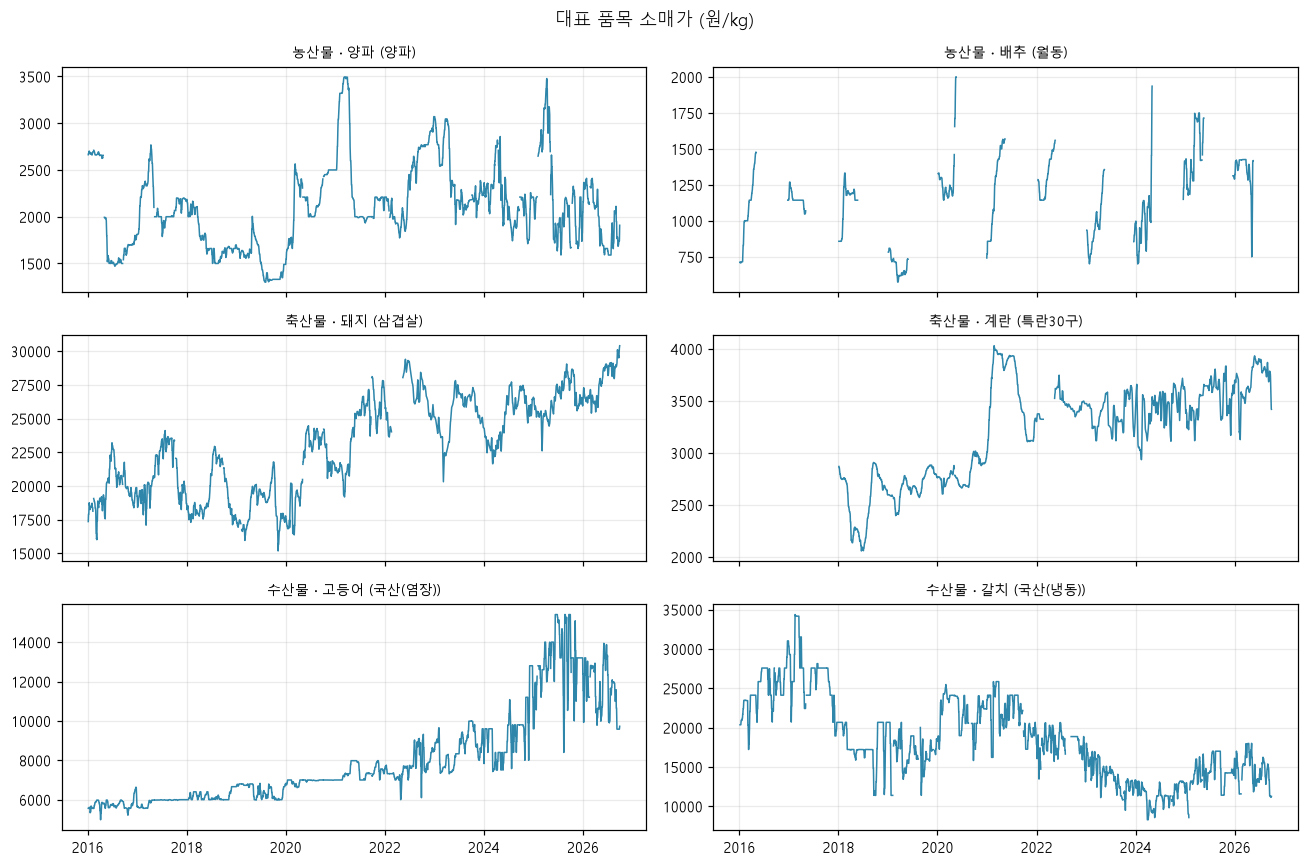

In [5]:
REP = [("agri", "양파"), ("agri", "배추"), ("livestock", "돼지"), ("livestock", "계란"), ("fishery", "고등어"), ("fishery", "갈치")]
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True)
for ax, (d, item) in zip(axes.flat, REP):
    s = ds[d][ds[d].item_nm == item]
    top = s.groupby(["vrty_nm", "grd_nm"]).date.nunique().idxmax()
    s = s[(s.vrty_nm == top[0]) & (s.grd_nm == top[1])].set_index("date").price_kg.asfreq("D")
    ax.plot(s.rolling(7, min_periods=3).mean(), lw=1, color="#2e86ab")
    ax.set_title(f"{NAMES[d]} · {item} ({top[0]})", fontsize=9); ax.grid(alpha=0.25)
fig.suptitle("대표 품목 소매가 (원/kg)"); plt.tight_layout()

## 4. 월별 계절성 — 그 해 평균 대비 월평균 가격

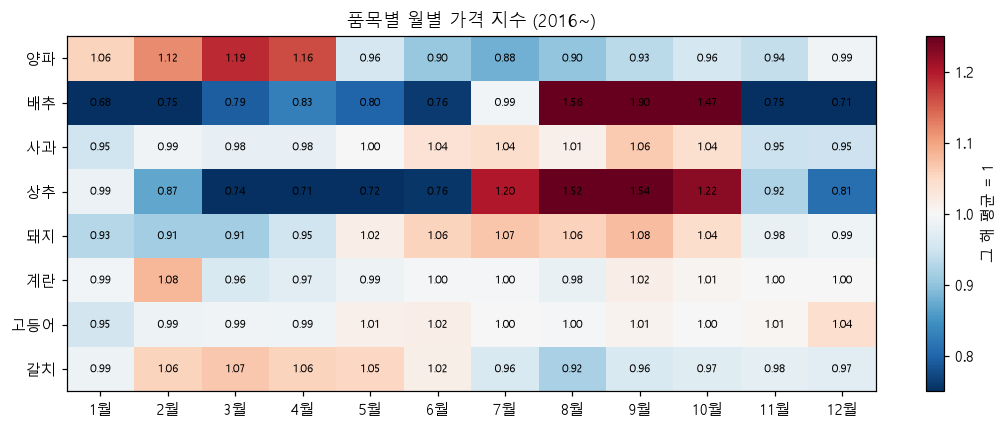

In [6]:
ITEMS = [("agri", "양파"), ("agri", "배추"), ("agri", "사과"), ("agri", "상추"), ("livestock", "돼지"), ("livestock", "계란"), ("fishery", "고등어"), ("fishery", "갈치")]
rows = {}
for d, item in ITEMS:
    s = ds[d][ds[d].item_nm == item]
    mon = s.groupby([s.date.dt.year, s.date.dt.month]).price_kg.mean()
    rows[item] = (mon / mon.groupby(level=0).transform("mean")).groupby(level=1).mean()
H = pd.DataFrame(rows).T
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(H.values, cmap="RdBu_r", vmin=0.75, vmax=1.25, aspect="auto")
ax.set_xticks(range(12), [f"{m}월" for m in H.columns]); ax.set_yticks(range(len(H)), H.index)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        ax.text(j, i, f"{H.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, label="그 해 평균 = 1"); ax.set_title("품목별 월별 가격 지수 (2016~)"); plt.tight_layout()

## 5. 가격과 관련 변수를 같은 시간축에

무엇이 가격과 같이 움직이고 무엇이 따로 노는지. 집계: sum14 = 최근 14일 합, mean14 = 14일 평균, sum28 = 28일 합

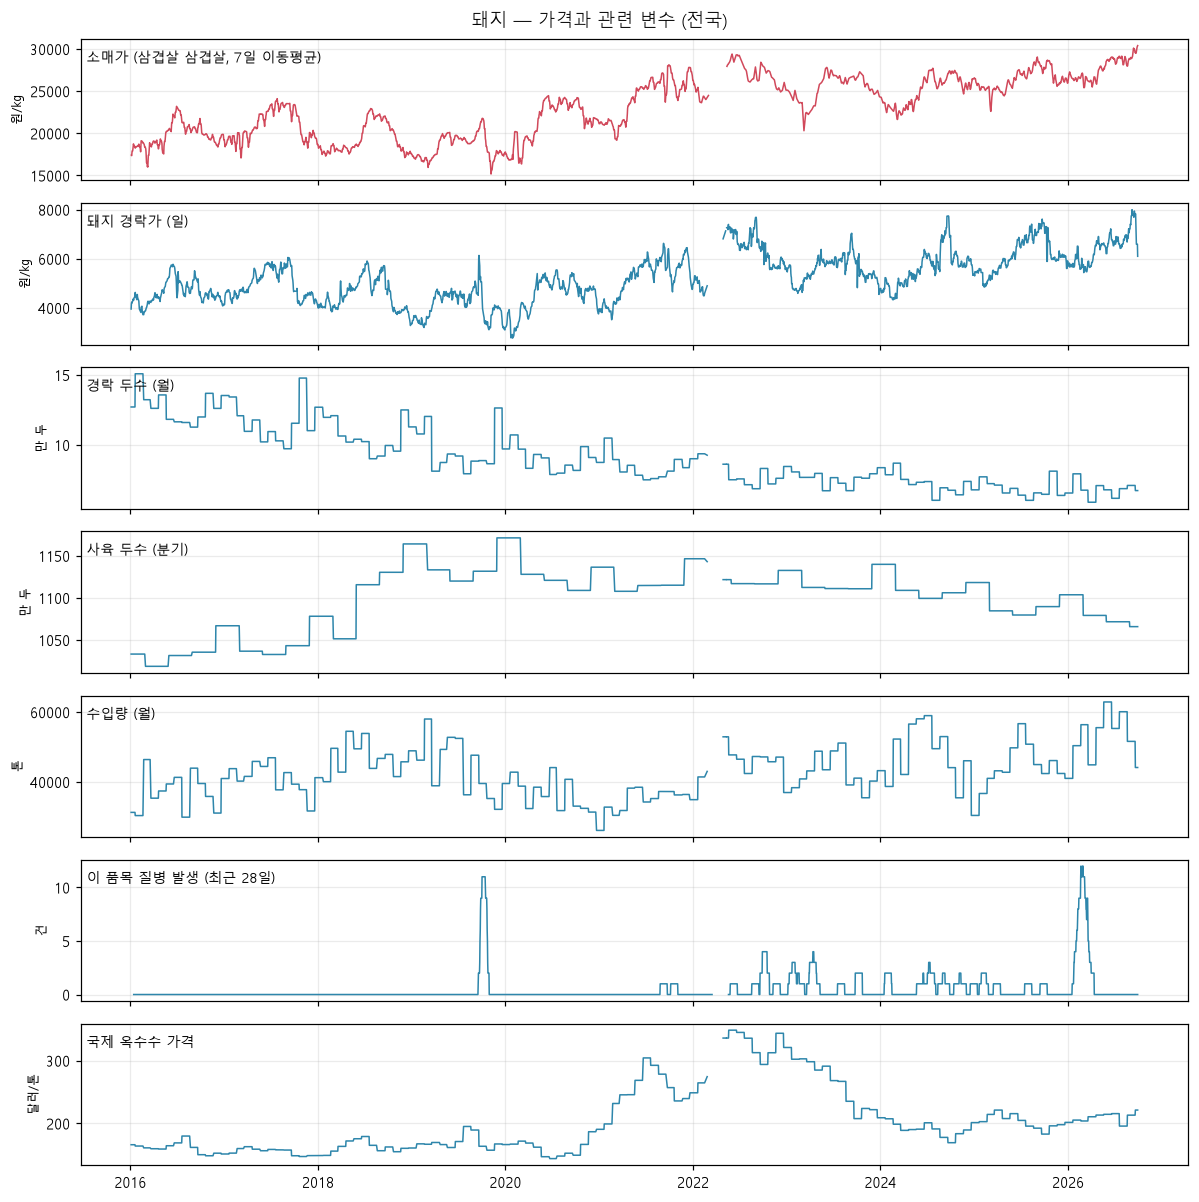

In [7]:
PANELS = {
    "agri": [("garak_price_kg", "가락시장 경락가", "원/kg", 1, None), ("garak_n_trades", "가락시장 거래 건수 (14일 평균)", "건", 1, "mean14"),
             ("wx_rain", "최근 2주 강수 (전국 평균)", "mm", 1, "sum14"), ("wx_temp_avg", "평균기온 (전국)", "℃", 1, None),
             ("wx_sunshine_hr", "일조시간 (전국, 14일 평균)", "시간", 1, "mean14"), ("usd_krw", "원/달러 환율", "원", 1, None)],
    "livestock": [("pig_auction_price_kg", "돼지 경락가 (일)", "원/kg", 1, None), ("auction_heads", "경락 두수 (월)", "만 두", 1e4, None),
                  ("census_heads", "사육 두수 (분기)", "만 두", 1e4, None), ("import_kg", "수입량 (월)", "톤", 1e3, None),
                  ("disease_cases", "이 품목 질병 발생 (최근 28일)", "건", 1, "sum28"), ("intl_옥수수", "국제 옥수수 가격", "달러/톤", 1, None)],
    "fishery": [("whsl_price_kg", "도매가", "원/kg", 1, None), ("catch_ton", "어획량 (월)", "톤", 1, None), ("catch_value_kkrw", "생산금액 (월)", "억원", 1e5, None),
                ("sea_temp_south", "남해 연근해 수온", "℃", 1, None), ("export_kg", "수출량 (월)", "톤", 1e3, None)],
}

def together(d, item):
    s = ds[d][ds[d].item_nm == item]
    s = s.assign(mon=s.date.dt.month)
    top = s.groupby(["vrty_nm", "grd_nm"]).agg(m=("mon", "nunique"), n=("date", "size")).sort_values(["m", "n"]).index[-1]
    s = s[(s.vrty_nm == top[0]) & (s.grd_nm == top[1])].set_index("date").sort_index()
    panels = [("price_kg", f"소매가 ({top[0]} {top[1]}, 7일 이동평균)", "원/kg", 1, "mean7")] + [p for p in PANELS[d] if p[0] in s and s[p[0]].notna().mean() > 0.3]
    fig, axes = plt.subplots(len(panels), 1, figsize=(11, 1.5 * len(panels) + 0.6), sharex=True)
    for ax, (c, name, unit, div, how) in zip(axes, panels):
        x = (s[c] / div).asfreq("D")
        if how:
            k = int(how[-2:]) if how[-2:].isdigit() else 7
            x = x.rolling(k, min_periods=max(2, k // 3)).sum() if how.startswith("sum") else x.rolling(k, min_periods=max(2, k // 3)).mean()
        ax.plot(x.interpolate(limit=10, limit_area="inside"), color="#d1495b" if c == "price_kg" else "#2e86ab", lw=1)
        ax.text(0.005, 0.92, name, transform=ax.transAxes, fontsize=9, va="top"); ax.set_ylabel(unit, fontsize=8)
        ax.ticklabel_format(axis="y", style="plain", useOffset=False); ax.grid(alpha=0.25)
    fig.suptitle(f"{item} — 가격과 관련 변수 (전국)"); plt.tight_layout()

together("livestock", "돼지")

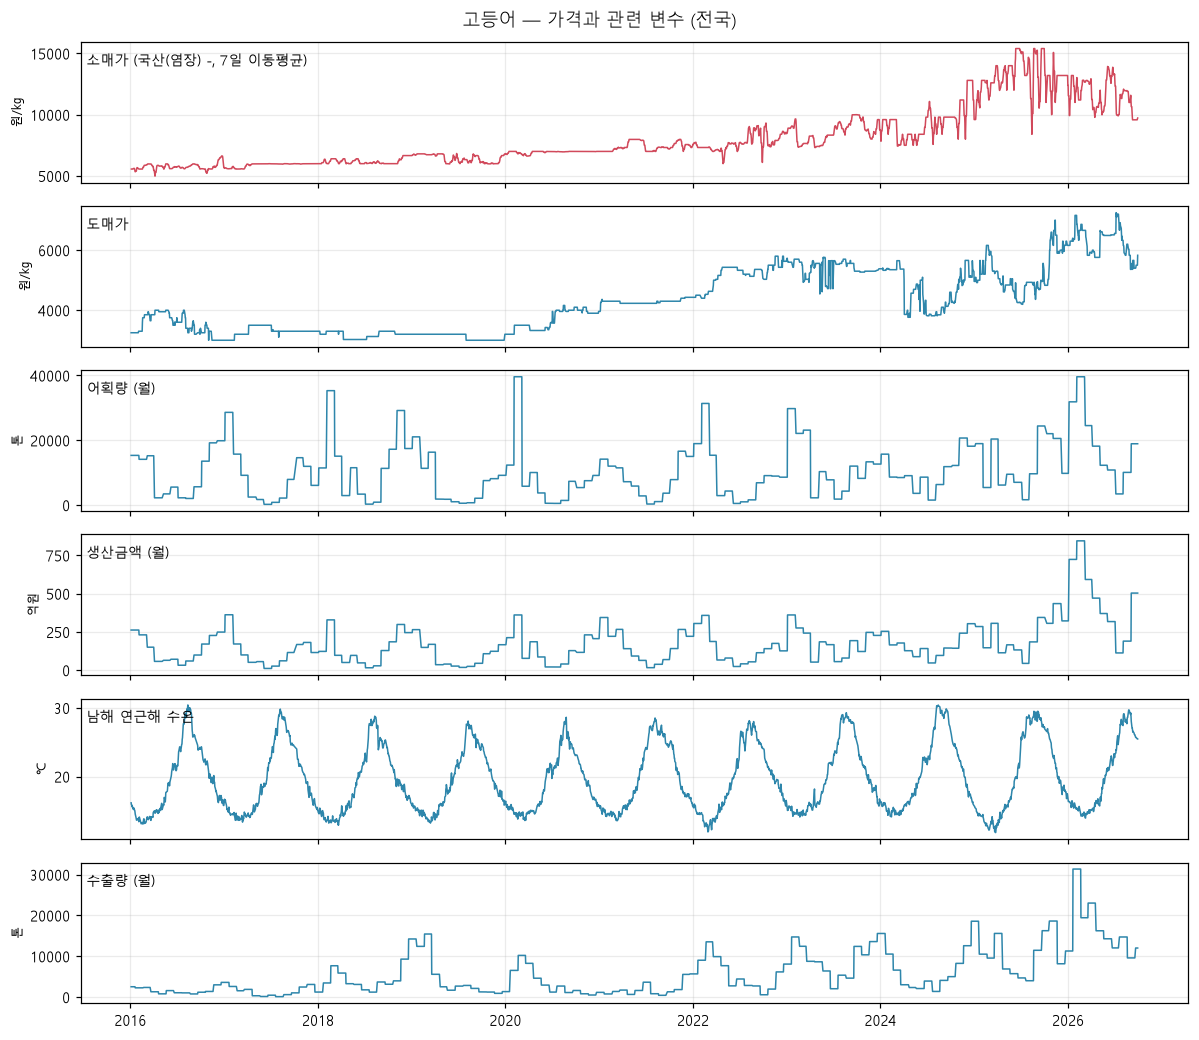

In [8]:
together("fishery", "고등어")

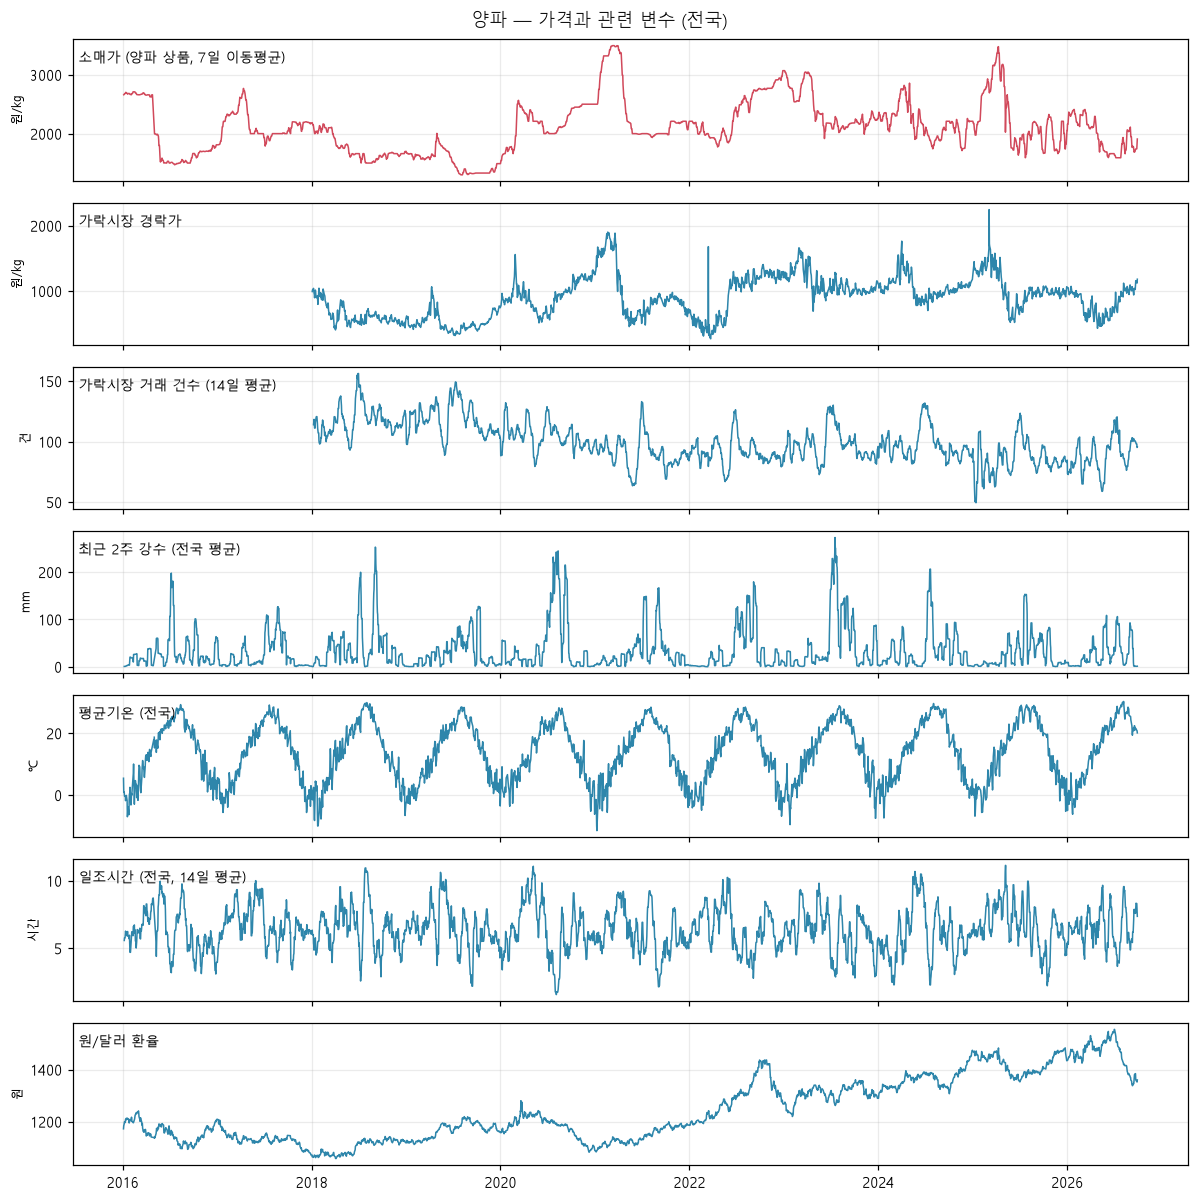

In [9]:
together("agri", "양파")